In [1]:
import gzip
import pandas as pd

DATA = "data/"
samples = pd.read_csv(DATA + "GTEx_Analysis_v11_Annotations_SampleAttributesDS.txt", sep="\t", low_memory=False)
subjects = pd.read_csv(DATA + "GTEx_Analysis_v11_Annotations_SubjectPhenotypesDS.txt", sep="\t")

print(subjects["SEX"].value_counts())
print(subjects["AGE"].value_counts().sort_index())

SEX
1    654
2    327
Name: count, dtype: int64
AGE
20-29     84
30-39     78
40-49    153
50-59    315
60-69    318
70-79     33
Name: count, dtype: int64


In [2]:
xls = pd.ExcelFile(DATA + "demontis2023_supp_tables.xlsx")
print(xls.sheet_names)

['1.Cohorts included', '2.Conditional COJO results', '3.ADHD2019 index variants', '4.sign test', '5.rg and h2SNP in ADHD cohorts', '6.Credible variants', '7.Genes mapped by crediblesets', '8.SynGO analysis', '9. Enricr analyses', '10. MAGMA gene set analysis', '11. TWAS DLPFC (PEC) genes', '12. TWAS DLPFC(PEC) transcripts', '13. Magma genes', '14. LDSC-SEG', '15.Cell type specific expres.', '16. rPTVs in ADHD risk genes', '17.LDsc rg published phenotypes', '18.LDsc UK biobank', '19.MiXeR results', '20. PGS analysis in PNC']


In [3]:
st7 = pd.read_excel(xls, sheet_name="7.Genes mapped by crediblesets")
print(st7.shape)
st7.head(10)

(79, 23)


,Supplementary Table 7. Genes mapped to sets of credible variants in FUMA. See supplementary information for datasets chosen in FUMA.,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22
0,######################\n# genes.txt\n# The lis...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,ensg,symbol,chr,start,end,strand,type,entrezID,HUGO,pLI,...,eqtlMapSNPs,eqtlMapminP,eqtlMapminQ,eqtlMapts,eqtlDirection,ciMap,ciMapts,minGwasP,IndSigSNPs,GenomicLocus
3,ENSG00000171960,PPIH,1,43124096,43142429,1,protein_coding,10465,PPIH,0.004755,...,0,NaN,NaN,NaN,NaN,Yes,Promoter_anchored_loops,0.0,rs549845,1
4,ENSG00000253313,C1orf210,1,43747554,43751288,-1,protein_coding,149466,C1orf210,0.00122,...,0,NaN,NaN,NaN,NaN,Yes,Adult_Cortex,0.0,rs549845,1
5,ENSG00000066322,ELOVL1,1,43829068,43833696,-1,protein_coding,64834,ELOVL1,0.223415,...,0,NaN,NaN,NaN,NaN,Yes,Adult_Cortex:Fetal_Cortex,0.0,rs549845,1
6,ENSG00000159479,MED8,1,43849588,43855479,-1,protein_coding,112950,MED8,0.000008,...,6,0.000012,0.001286,PsychENCODE_eQTLs:CMC_SVA_cis,-,Yes,Adult_Cortex:Fetal_Cortex,0.0,rs549845,1
7,ENSG00000198198,SZT2,1,43855553,43918321,1,protein_coding,23334,SZT2,0.0,...,0,NaN,NaN,NaN,NaN,Yes,Adult_Cortex:Fetal_Cortex,0.0,rs549845,1
8,ENSG00000178922,HYI,1,43916824,43919660,-1,protein_coding,81888,HYI,0.0,...,1,0.000371,0.025808,PsychENCODE_eQTLs,+,No,NaN,0.0,rs549845,1
9,ENSG00000142949,PTPRF,1,43990858,44089343,1,protein_coding,5792,PTPRF,0.999998,...,0,NaN,NaN,NaN,NaN,Yes,EP_links_oneway:Promoter_anchored_loops:Adult_...,0.0,rs549845,1


In [5]:
import os
st7 = pd.read_excel(xls, sheet_name="7.Genes mapped by crediblesets", header=3)
adhd = st7.dropna(subset=["ensg"])
adhd = adhd[adhd["ensg"].astype(str).str.startswith("ENSG")]
adhd_ids = adhd["ensg"].str.split(".").str[0].unique()
print(len(adhd_ids), "ADHD risk genes")
print(adhd["chr"].value_counts().sort_index())

# How many ADHD genes passed expression filtering and were tested in each region
import glob
de = {}
for f in sorted(glob.glob("deseq_results/*_sex_DE.csv")):
    region = os.path.basename(f).replace("_sex_DE.csv", "")
    de[region] = pd.read_csv(f).set_index("gene_id")
    print(f"{region}: {de[region].index.isin(adhd_ids).sum()} of {len(adhd_ids)} ADHD genes tested")

pd.Series(adhd_ids, name="gene_id").to_csv("adhd_genes.csv", index=False)

76 ADHD risk genes
chr
1     10
3     30
4      3
5      1
6      1
7      1
8     20
10     1
12     1
14     1
16     1
18     4
20     2
Name: count, dtype: int64
anterior_cingulate: 70 of 76 ADHD genes tested
caudate: 69 of 76 ADHD genes tested
frontal_cortex: 70 of 76 ADHD genes tested
nucleus_accumbens: 68 of 76 ADHD genes tested
putamen: 68 of 76 ADHD genes tested


In [8]:
import numpy as np
import matplotlib.pyplot as plt
genes = pd.read_csv("region_data/gene_annotation.csv", index_col=0)

# Universe = genes tested in all five regions that have length and GC data
common = set.intersection(*[set(d.index) for d in de.values()])
feat = genes.loc[genes.index.intersection(list(common)), ["length", "gc"]].dropna()
mean_expr = pd.concat([de[r].loc[feat.index, "baseMean"] for r in de], axis=1).mean(axis=1)
feat["expr"] = np.log10(mean_expr + 1)

feat["bin"] = (pd.qcut(feat["expr"], 10, labels=False).astype(str) + "_" +
               pd.qcut(feat["length"], 10, labels=False).astype(str) + "_" +
               pd.qcut(feat["gc"], 3, labels=False).astype(str))

adhd_in = [g for g in adhd_ids if g in feat.index]
print(len(feat), "genes in universe;", len(adhd_in), "ADHD genes included")

23349 genes in universe; 68 ADHD genes included


In [9]:
male   = pd.DataFrame({r: (d.loc[feat.index, "padj"] < 0.05) & (d.loc[feat.index, "log2FoldChange"] > 0) for r, d in de.items()})
female = pd.DataFrame({r: (d.loc[feat.index, "padj"] < 0.05) & (d.loc[feat.index, "log2FoldChange"] < 0) for r, d in de.items()})

obs_m = int(male.loc[adhd_in].values.sum())
obs_f = int(female.loc[adhd_in].values.sum())

rng = np.random.default_rng(134)
others = feat.drop(index=adhd_in)
pools = {b: grp.index.values for b, grp in others.groupby("bin")}
need = feat.loc[adhd_in, "bin"].value_counts()

null_m, null_f = [], []
for i in range(1000):
    pick = np.concatenate([rng.choice(pools[b], size=n, replace=len(pools[b]) < n) for b, n in need.items()])
    null_m.append(male.loc[pick].values.sum())
    null_f.append(female.loc[pick].values.sum())
null_m, null_f = np.array(null_m), np.array(null_f)

p_m = (np.sum(null_m >= obs_m) + 1) / 1001
p_f = (np.sum(null_f >= obs_f) + 1) / 1001
print(f"Male-biased pairs:   ADHD = {obs_m}, random mean = {null_m.mean():.1f}, p = {p_m:.3f}")
print(f"Female-biased pairs: ADHD = {obs_f}, random mean = {null_f.mean():.1f}, p = {p_f:.3f}")

Male-biased pairs:   ADHD = 12, random mean = 18.6, p = 0.909
Female-biased pairs: ADHD = 13, random mean = 13.3, p = 0.561


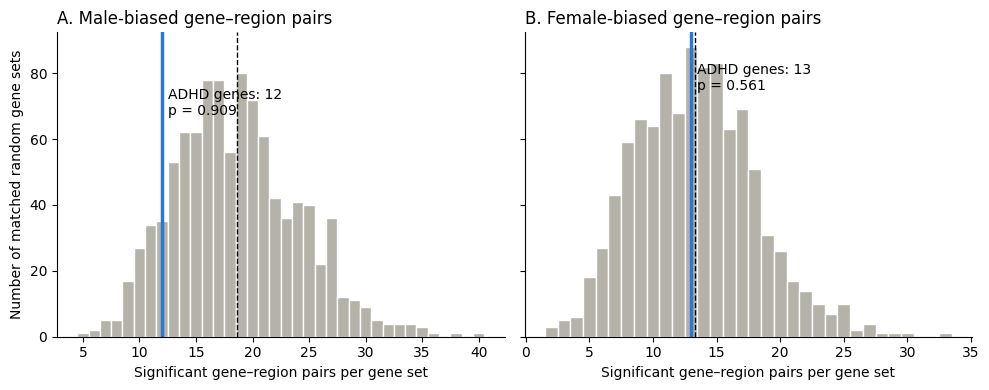

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, null, obs, p, title in [(axes[0], null_m, obs_m, p_m, "A. Male-biased gene–region pairs"),
                                 (axes[1], null_f, obs_f, p_f, "B. Female-biased gene–region pairs")]:
    bins = np.arange(null.min() - 0.5, max(null.max(), obs) + 1.5, 1)
    ax.hist(null, bins=bins, color="#b4b2a9", edgecolor="white")
    ax.axvline(obs, color="#2a78d6", linewidth=2.5)
    ax.text(obs + 0.5, ax.get_ylim()[1] * 0.9, f"ADHD genes: {obs}\np = {p:.3f}", va="top")
    ax.set_title(title, loc="left")
    ax.set_xlabel("Significant gene–region pairs per gene set")
    ax.spines[["top", "right"]].set_visible(False)
    ax.axvline(null.mean(), color="black", linestyle="--", linewidth=1)
axes[0].set_ylabel("Number of matched random gene sets")
plt.tight_layout()
plt.savefig("figure1_permutation.png", dpi=300)
plt.show()

In [11]:
rows = []
for r, d in de.items():
    sub = d.loc[d.index.isin(adhd_in) & (d["padj"] < 0.05)]
    for g, row in sub.iterrows():
        rows.append({"Gene": genes.loc[g, "gene_name"], "Chromosome": genes.loc[g, "chrom"],
                     "Brain region": r, "log2 fold change (M/F)": round(row["log2FoldChange"], 3),
                     "Adjusted p-value": f"{row['padj']:.2e}",
                     "Direction": "Male-biased" if row["log2FoldChange"] > 0 else "Female-biased"})
table1 = pd.DataFrame(rows).sort_values(["Direction", "Gene", "Brain region"])
table1.to_csv("table1_sex_biased_adhd_genes.csv", index=False)
print(len(table1), "rows;", table1["Gene"].nunique(), "unique genes")
table1

25 rows; 15 unique genes


,Gene,Chromosome,Brain region,log2 fold change (M/F),Adjusted p-value,Direction
8,ABHD5,3,caudate,-0.174,2.55e-02,Female-biased
0,ELOVL1,1,anterior_cingulate,-0.319,1.71e-02,Female-biased
7,GASK1A,3,caudate,-0.233,3.89e-02,Female-biased
19,GASK1A,3,putamen,-0.332,1.71e-02,Female-biased
16,XRN2,20,caudate,-0.113,2.01e-02,Female-biased
11,ZNF197,3,caudate,-0.102,2.08e-02,Female-biased
21,ZNF197,3,putamen,-0.109,1.82e-02,Female-biased
5,ZNF34,8,anterior_cingulate,-0.120,4.52e-02,Female-biased
2,ZNF660,3,anterior_cingulate,-0.230,1.05e-02,Female-biased
10,ZNF660,3,caudate,-0.232,8.44e-03,Female-biased
